# Bước B0 (phần so sánh) - gom 3 lần huấn luyện 30 epoch Sequential Forecast LSTM có Q (hạt giống 111, 222, 333), đo nhiễu hạt giống cùng giao thức 30 epoch (ngưỡng luật chọn B*), kiểm B0 lặp lại A4 ở các epoch chung, so với A4 và tác giả
# BiasCast, xuất dự báo theo hợp đồng NPZ của bộ đánh giá
 Bài: Konold và cs., HESS 30:5067-5096 (2026). Kế hoạch: Document/01_Plan/02_Pipeline.md Mục 5.1, 7 (dòng B0, B*), 9.5.
# Notebook Kaggle "02_B0_LamaHCEExt_Compare": Accelerator = None (CPU), Internet = On, Persistence = Files only,
# Environment = Pin to original environment. Add Input:
   - Output 3 notebook 01_B0_LamaHCEExt_Train_Seed111 / _Seed222 / _Seed333 (Version 1 cả ba);
   - Output 3 notebook 03_A4_LamaHCEExt_Retrain_Seed111 (Version 1), _Seed222 (Version 2), _Seed333 (Version 2) -
     trọng số mọi epoch, validation từng epoch, test_results.p của A4;
   - Output 02_A3_LamaHCEExt_Benchmarks (người 1, Version 1) - ngữ cảnh quan trắc, persistence, diện tích cho NPZ;
   - Dataset lamah-ce-ext - chỉ số test của tác giả.
 Không cần GPU, không cần thư viện NeuralHydrology: test_results.p chỉ cần xarray để đọc, trọng số đọc bằng torch có sẵn.
 Dán nguyên tệp vào notebook rồi Save & Run All, không sửa dòng nào.

# MỤC LỤC
   Phần 1 - Tìm Input, kiểm sha256 tệp của 3 run B0 và 3 run A4, môi trường
   Phần 2 - Bảng 3 hạt giống B0 cạnh A4 và tác giả, ngưỡng luật B*
   Phần 3 - B0 lặp lại A4 ở các epoch chung
   Phần 4 - So từng lưu vực, nhiễu hạt giống, kiểm định ghép cặp
   Phần 5 - Hình
   Phần 6 - Dựng NPZ theo hợp đồng bộ đánh giá và kiểm lại
   Phần 7 - Lưu kết quả và môi trường

bước,hạt giống,Version,thư mục Input,thư mục run,commit thư viện,GPU,torch,epoch best_model.pt,số epoch
B0,111,1,notebooks/hunhngcthng/01-b0-lamahceext-train-seed111,b0_runs/B0_SeqLSTM_Q_seed111_2510_175050,f229e02,Tesla T4,2.11.0+cu128,25,30
B0,222,1,notebooks/hunhngcthng/01-b0-lamahceext-train-seed222,b0_runs/B0_SeqLSTM_Q_seed222_2510_175613,f229e02,Tesla T4,2.11.0+cu128,15,30
B0,333,1,notebooks/hunhngcthng/01-b0-lamahceext-train-seed333,b0_runs/B0_SeqLSTM_Q_seed333_2510_232832,f229e02,Tesla T4,2.11.0+cu128,14,30
A4,111,1,notebooks/hunhngcthng/03-a4-lamahceext-retrain-seed111,a4_runs/A4_SeqLSTM_Q_seed111_2310_193149,dda45fc,Tesla T4,2.11.0+cu128,11,16
A4,222,2,notebooks/hunhngcthng/03-a4-lamahceext-retrain-seed222,a4_runs/A4_SeqLSTM_Q_seed222_2310_194052,dda45fc,Tesla T4,2.11.0+cu128,15,20
A4,333,2,notebooks/hunhngcthng/03-a4-lamahceext-retrain-seed333,a4_runs/A4_SeqLSTM_Q_seed333_2310_232038,dda45fc,Tesla T4,2.11.0+cu128,14,19


tệp,111,222,333
best_model.pt,ĐẠT,ĐẠT,ĐẠT
config.yml,ĐẠT,ĐẠT,ĐẠT
events.out.tfevents.*,ĐẠT,ĐẠT,ĐẠT
output.log,ĐẠT,ĐẠT,ĐẠT
test/best_model/test_metrics.csv,ĐẠT,ĐẠT,ĐẠT
test/best_model/test_results.p,ĐẠT,ĐẠT,ĐẠT
train_data/train_data_scaler.yml,ĐẠT,ĐẠT,ĐẠT


tệp,111,222,333
best_model.pt,ĐẠT,ĐẠT,ĐẠT
config.yml,ĐẠT,ĐẠT,ĐẠT
output.log,ĐẠT,ĐẠT,ĐẠT
test/best_model/test_metrics.csv,ĐẠT,ĐẠT,ĐẠT
test/best_model/test_results.p,ĐẠT,ĐẠT,ĐẠT
train_data/train_data_scaler.yml,ĐẠT,ĐẠT,ĐẠT


tệp,đường dẫn,KB
A3_persistence_predictions.npz,notebooks/hunhthanhnhn/02-a3-lamahceext-benchmarks/a3_output/A3_persistence_predictions.npz,8136.7
A3_Q_source_window.npz,notebooks/hunhthanhnhn/02-a3-lamahceext-benchmarks/a3_output/A3_Q_source_window.npz,3349.0
test_metrics.csv của tác giả,datasets/hunhngcthng/.../test/best_model/test_metrics.csv,18.8


mục,giá trị
Python,3.13.15
numpy,2.1.3
pandas,2.3.3
xarray,2025.12.0
scipy,1.16.3
matplotlib,3.10.0
torch,2.11.0+cpu
Số CPU,4
Ngày dựng ảnh Kaggle,20261022-041801


...

bước,đại lượng,phân vị 50%,phân vị 75%,phân vị 90%,phân vị 100%
B0,độ lệch chuẩn 3 hạt giống,0.0197,0.0360,0.0636,3.0401
B0,max - min 3 hạt giống,0.0379,0.0686,0.1208,5.8568
B0,|tác giả - trung bình|,0.0182,0.0358,0.0726,69.8173
B0,"tỉ lệ lưu vực tác giả trong [min, max]",0.4911,-,-,-
A4,độ lệch chuẩn 3 hạt giống,0.0207,0.0353,0.0644,3.9117
A4,max - min 3 hạt giống,0.0396,0.0681,0.1212,7.4043
A4,|tác giả - trung bình|,0.0171,0.0353,0.0611,69.3014
A4,"tỉ lệ lưu vực tác giả trong [min, max]",0.5222,-,-,-


mức NSE,số lưu vực,B0,A4
< 0,3,1.2678,1.8179
0 - 0.5,64,0.0312,0.0291
0.5 - 0.7,155,0.0225,0.0267
0.7 - 0.85,153,0.0193,0.0202
>= 0.85,75,0.0075,0.0100


basin,B0 111,B0 222,B0 333,tác giả,B0 max - min
758,-11.8781,-7.5357,-6.0213,-78.2956,5.8568
742,-4.8799,-2.6180,-2.7566,-43.9407,2.2619
411,-0.4641,0.2105,0.2402,0.2206,0.7043
754,0.6072,0.0552,0.4974,-0.0197,0.5520
119,0.5786,0.5499,0.1039,0.1171,0.4747
312,0.3560,-0.0523,0.3811,0.4104,0.4334
523,0.7816,0.3753,0.7810,0.7699,0.4063
568,0.6985,0.6254,0.3114,0.6402,0.3871
437,0.1074,0.3599,0.4761,0.4582,0.3688
430,0.1589,0.4772,0.4644,0.4399,0.3183


họ,trái,phải,số cặp,trái tốt hơn,trái kém hơn,trung bình hiệu,trung vị hiệu,Cohen's dz,p Wilcoxon,p Holm
B0 với tác giả,B0 111,tác giả,450,245,205,0.2380,0.0028,0.0656,0.1478,0.2644
B0 với tác giả,B0 222,tác giả,450,248,202,0.2540,0.0037,0.0658,0.0480,0.1439
B0 với tác giả,B0 333,tác giả,450,253,197,0.2563,0.0048,0.0654,0.1322,0.2644
cặp hạt giống B0,B0 111,B0 222,450,227,223,-0.0160,0.0003,-0.0662,0.7138,1.0000
cặp hạt giống B0,B0 111,B0 333,450,233,217,-0.0183,0.0018,-0.0604,0.9300,1.0000
cặp hạt giống B0,B0 222,B0 333,450,234,216,-0.0023,0.0013,-0.0230,0.1887,0.5660
B0 với A4 cùng hạt giống,B0 111,A4 111,450,260,190,0.0110,0.0043,0.1061,0.0005,0.0014
B0 với A4 cùng hạt giống,B0 222,A4 222,450,0,0,0.0000,0.0000,-,1.0000,1.0000
B0 với A4 cùng hạt giống,B0 333,A4 333,450,0,0,0.0000,0.0000,-,1.0000,1.0000


=> Mốc nhiễu B0: trung vị độ lệch chuẩn NSE theo lưu vực 0.0197 (A4 0.0207); cặp hạt giống B0: |trung vị hiệu| lớn nhất 0.0018, 0/3 cặp p Holm < 0.05. Chạy đủ 30 epoch ở hạt giống 111 (epoch 25 so với 11): trung vị hiệu +0.0043, dz +0.106, B0 tốt hơn ở 260/450 lưu vực. Chạy Phần 5.


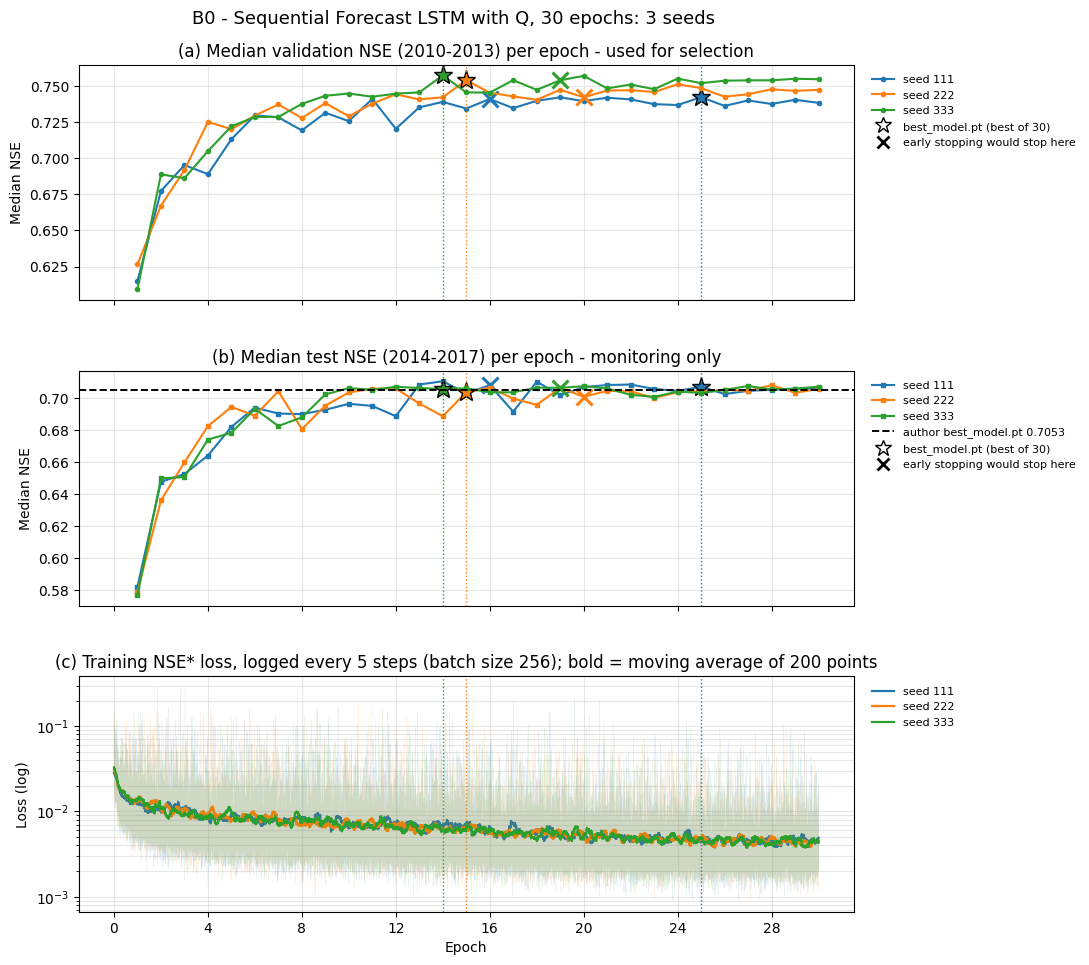

Hình: Ba hạt giống 111, 222, 333 (ba màu), chung trục epoch; sao và đường chấm dọc là epoch lưu thành best_model.pt (25, 15, 14), chữ x là epoch mà quy tắc dừng sớm của tác giả sẽ dừng (16, 20, 19; lấy từ A4, trùng B0 từng bit tới đó - Phần 3). Hạt giống có sao nằm sau chữ x (111) là trường hợp dừng sớm bỏ lỡ epoch tốt nhất. (a) NSE trung vị validation, thước đo duy nhất để chọn epoch. (b) NSE trung vị test mỗi epoch, chỉ để theo dõi: best_model.pt cho 0,7072, 0,7038, 0,7059, thấp hơn epoch test cao nhất 0,0035, 0,0045, 0,0019. (c) Loss NSE* từng lô (mờ, 25650 điểm mỗi hạt giống) và trung bình trượt (đậm), trục log: trung bình trượt giảm từ 0,0281, 0,0307, 0,0329 xuống 0,0049, 0,0044, 0,0043 ở epoch 30; so với (a) để thấy đoạn loss huấn luyện còn giảm trong khi NSE validation không tăng thêm.


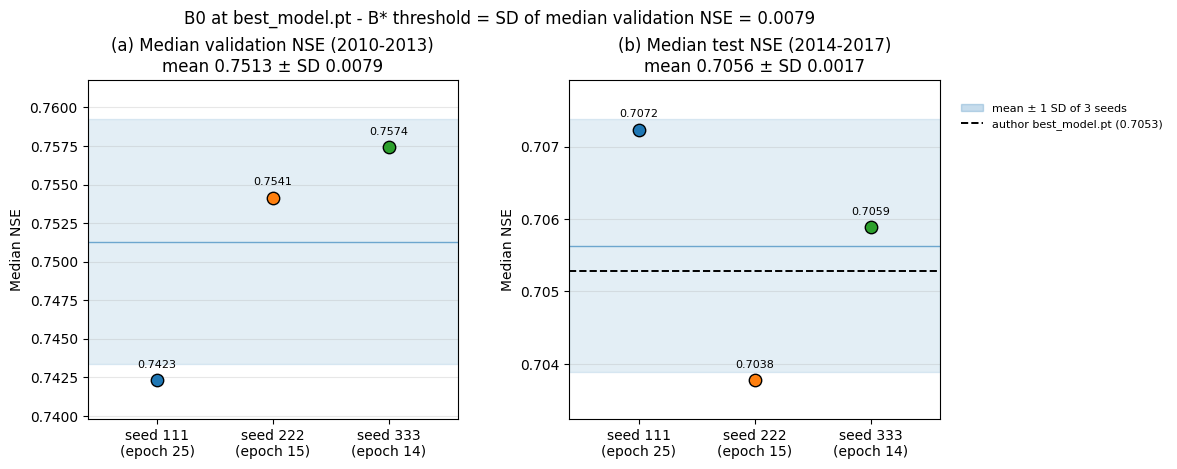

Hình: Mỗi chấm là một hạt giống tại best_model.pt (epoch ghi dưới trục). (a) NSE trung vị validation 0,7423, 0,7541, 0,7574; dải xanh là trung bình ± 1 độ lệch chuẩn (0,7513 ± 0,0079) - độ lệch chuẩn này là ngưỡng của luật chọn B*: cấu hình B1b-B3 kém cấu hình tốt nhất không quá 0,0079 được coi là ngang nhau. (b) NSE trung vị test 0,7072, 0,7038, 0,7059 (trung bình 0,7056 ± 0,0017), nét đứt là best_model.pt của tác giả 0,7053.


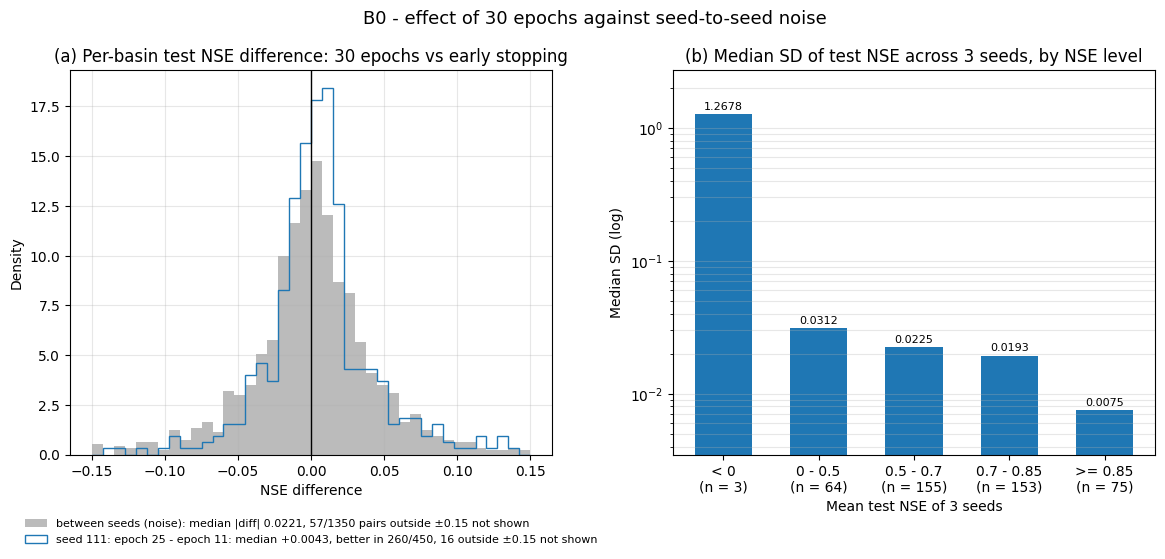

Hình: (a) Đường màu: chênh NSE test từng lưu vực trong cùng một run B0 giữa best_model.pt sau 30 epoch và epoch tốt nhất nếu dừng sớm (hạt giống 111 epoch 25 so với 11: trung vị chênh 0,0043, tốt hơn ở 260/450 lưu vực, khoảng tứ phân vị 0,0327; hạt giống còn lại chọn cùng epoch nên chênh bằng 0). Nền xám: chênh giữa các cặp hạt giống (mốc nhiễu), trung vị trị tuyệt đối 0,0221, khoảng tứ phân vị 0,0444 (dùng khoảng tứ phân vị thay độ lệch chuẩn vì vài lưu vực NSE âm sâu kéo lệch). Wilcoxon (Phần 4, cùng con số vì epoch 11 của B0 trùng A4 từng bit): p Holm 0,0014, dz 0,106 - đọc cùng độ lớn chênh so với mốc nhiễu, không đọc p một mình. (b) Trung vị độ lệch chuẩn NSE test qua 3 hạt giống theo mức NSE của lưu vực (thang log), từ mức thấp tới cao: 1,2678, 0,0312, 0,0225, 0,0193, 0,0075 (mức thấp nhất gấp 168,9 lần mức cao nhất); so mô hình theo từng lưu vực ở bước B, C đặt cạnh mức nhiễu của đúng mức NSE đó.
=> Đã lưu 3 hình vào /kaggle/working/b0_compare - chạy Phần 6.


mục,đạt
Lịch test 2014-2017 theo config.yml của B0,ĐẠT
Ngày nguồn persistence = ngày đích - 1,ĐẠT
ID nguồn Q trùng ID persistence,ĐẠT
Lịch nguồn Q bắt đầu trước kỳ test 1 ngày,ĐẠT
"obs, persistence khớp Q gốc / diện tích",ĐẠT
Đủ 451 ID,ĐẠT


hạt giống,tệp,MB,selected_epoch,clip_to_zero,dự báo âm trước chặn,ngày-lưu vực có sim,lỗi hợp đồng,max |ΔNSE| so với thư viện,NaN NSE trùng thư viện,mặt nạ obs trùng A3,max |obs run - obs A3|,NSE trung vị từ NPZ,đạt
111,SeqLSTM_Q_B0_seed111_test_S0_lead1.npz,9.974117,25,True,1584,652644,-,0.000000,True,True,0.000011,0.707234,True
222,SeqLSTM_Q_B0_seed222_test_S0_lead1.npz,9.981151,15,True,2261,652644,-,0.000000,True,True,0.000011,0.703778,True
333,SeqLSTM_Q_B0_seed333_test_S0_lead1.npz,9.978291,14,True,1978,652644,-,0.000000,True,True,0.000011,0.705890,True


=> Đạt. 3 tệp ở /kaggle/working/b0_compare/contracts; bộ đánh giá đọc bằng --extra-contract. Chạy Phần 7.


tệp,KB,sha256
B0_A4_reproduction.csv,0.5,956ca3299af3
B0_A4_reproduction_by_epoch.csv,1.2,d2b62763532b
B0_Noise.png,112.8,b7cefea95f06
B0_Seeds.png,390.6,d9e87cc28428
B0_Summary.png,99.7,3374259509d8
B0_paired_tests.csv,1.3,234af7e6ab03
B0_seed_noise_by_basin.csv,119.5,ba0413d8bb0c
B0_seed_stats.csv,1.1,8c78a5840482
B0_seed_table.csv,1.0,bd28b06d2fc6
B0_timing.csv,0.5,db943e3a1029


=> Xong B0. Tải 3 hình B0_Seeds.png, B0_Summary.png, B0_Noise.png về Workspace/05_Training/02_B0_LamaHCEExt_Compare/Figures/; Output này (Save Version) gắn làm Input cho bộ đánh giá.


In [1]:
# %% Phần 1 - Tìm Input, kiểm sha256 tệp của 3 run B0 và 3 run A4, môi trường
# Mỗi notebook hạt giống có <b0|a4>_output/environment.json (hạt giống, thư mục run, commit thư viện, torch) và
# manifest.csv (tệp chính của run kèm sha256, đường dẫn tính từ /kaggle/working của notebook đó: B0 7 tệp - thêm tệp
# tensorboard, A4 6 tệp). Nhận Output theo environment.json (không theo tên đường dẫn), tính lại sha256 từng tệp để chắc
# Input gắn đúng bản lưu và không hỏng khi chép. Tìm thêm 2 tệp ngữ cảnh của A3 (tên theo 02_A3_LamaHCEExt_Benchmarks.py
# dòng 805, 964) và chỉ số test của tác giả. Phần 1 chưa đạt thì dừng notebook.
import hashlib
import json
import os
import platform
from importlib import metadata
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import HTML, display

IS_KAGGLE = Path("/kaggle/working").exists()
INPUT_ROOT = Path(os.environ.get("B0_INPUT_ROOT", "/kaggle/input" if IS_KAGGLE else "b0_compare_input"))
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("b0_compare_work")
OUT_DIR = WORK_DIR / "b0_compare"
SEEDS = [111, 222, 333]
RUNS = {"B0": {"versions": {111: 1, 222: 1, 333: 1}, "output": "b0_output", "notebook": "01_B0_LamaHCEExt_Train_Seed{}",
               "commit": "f229e02bf98cbd979835a4b6cd503d0e3adb8bc3", "n_files": 7},
        "A4": {"versions": {111: 1, 222: 2, 333: 2}, "output": "a4_output", "notebook": "03_A4_LamaHCEExt_Retrain_Seed{}",
               "commit": "dda45fcf19ee7ffd481b9d192778539df46fb074", "n_files": 6}}
A3_VERSION = 1
A3_FILES = ["A3_persistence_predictions.npz", "A3_Q_source_window.npz"]
AUTHOR_METRICS_REL = ("Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/"
                      "Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/test/best_model/test_metrics.csv")
ENV_LIBS = ["numpy", "pandas", "xarray", "scipy", "matplotlib", "torch"]
OUT_DIR.mkdir(parents=True, exist_ok=True)


def show(title, df, digits=4):
    # Bảng HTML: số thực làm tròn `digits` chữ số, ô trống hiện "-".
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(df.style.hide(axis="index").format(precision=digits, na_rep="-"))


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as fp:
        for chunk in iter(lambda: fp.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def short(path, keep=3):
    # Đường dẫn tính từ INPUT_ROOT, dài thì giữ 2 cấp đầu và `keep` cấp cuối.
    parts = Path(path).relative_to(INPUT_ROOT).parts
    return "/".join(parts) if len(parts) <= keep + 2 else "/".join(parts[:2] + ("...",) + parts[-keep:])


def unique_file(root, name):
    # Đúng một tệp tên `name` dưới `root`; báo lỗi rõ nếu không có hoặc có nhiều (gắn trùng Input).
    hits = sorted(root.rglob(name))
    if len(hits) != 1:
        raise FileNotFoundError(f"Cần đúng 1 tệp '{name}' dưới {root}, thấy {len(hits)}: {hits}")
    return hits[0]


# (1) Output 3 notebook hạt giống của mỗi bước: nhận theo environment.json
ROOTS, ENVS = {}, {}                     # ROOTS[bước][hạt giống] = thư mục tương ứng /kaggle/working của notebook đó
for step, spec in RUNS.items():
    ROOTS[step] = {}
    for env_path in sorted(INPUT_ROOT.rglob(f"{spec['output']}/environment.json")):
        seed = json.loads(env_path.read_text(encoding="utf-8")).get("seed")
        if seed in ROOTS[step]:
            raise RuntimeError(f"{step} hạt giống {seed} có ở 2 Input: {ROOTS[step][seed]}, {env_path.parent.parent}")
        ROOTS[step][seed] = env_path.parent.parent
    if sorted(ROOTS[step]) != SEEDS:
        raise RuntimeError(f"Cần Output đúng 3 notebook {step} {SEEDS}, thấy {sorted(ROOTS[step])} - kiểm Add Input")
    ENVS[step] = {s: json.loads((r / spec["output"] / "environment.json").read_text(encoding="utf-8"))
                  for s, r in ROOTS[step].items()}
show("Output 6 notebook hạt giống", pd.DataFrame([{
    "bước": step, "hạt giống": s, "Version": RUNS[step]["versions"][s], "thư mục Input": short(ROOTS[step][s]),
    "thư mục run": e["run_dir"], "commit thư viện": e["neuralhydrology_commit"][:7], "GPU": e["gpu"],
    "torch": e["libs"]["torch"], "epoch best_model.pt": e["summary"]["saved_epoch"], "số epoch": e["summary"]["n_epochs"]}
    for step in RUNS for s, e in sorted(ENVS[step].items())]))

# (2) Kiểm sha256 từng tệp trong manifest.csv
rows = []
for step, spec in RUNS.items():
    for s, root in sorted(ROOTS[step].items()):
        man = pd.read_csv(root / spec["output"] / "manifest.csv")
        for rel, digest in zip(man["tệp"], man["sha256"]):
            f = root / rel
            got = sha256(f) if f.exists() else "THIẾU"
            rows.append({"bước": step, "hạt giống": s, "tệp": rel.split("/", 2)[-1],
                         "KB": round(f.stat().st_size / 1e3, 1) if f.exists() else None,
                         "sha256 khớp": "ĐẠT" if got == digest else "KHÔNG"})
SHA_DF = pd.DataFrame(rows)
SHA_DF["tệp"] = SHA_DF["tệp"].str.replace(r"^events\.out\.tfevents\..*", "events.out.tfevents.*", regex=True)
for step in RUNS:
    show(f"sha256 tệp chính của 3 run {step} (so với manifest.csv của từng notebook)",
         SHA_DF[SHA_DF["bước"] == step].pivot(index="tệp", columns="hạt giống", values="sha256 khớp").reset_index())

# (3) Ngữ cảnh A3 và chỉ số test của tác giả
A3_PATHS = {name: unique_file(INPUT_ROOT, name) for name in A3_FILES}
author_hits = [p for p in INPUT_ROOT.rglob("test_metrics.csv") if p.as_posix().endswith(AUTHOR_METRICS_REL)]
if len(author_hits) != 1:
    raise FileNotFoundError(f"Cần đúng 1 tệp chỉ số test của tác giả ({AUTHOR_METRICS_REL}), thấy {len(author_hits)} - gắn lamah-ce-ext")
AUTHOR_METRICS_PATH = author_hits[0]
show("Tệp ngữ cảnh", pd.DataFrame(
    [{"tệp": n, "đường dẫn": short(p), "KB": round(p.stat().st_size / 1e3, 1)} for n, p in A3_PATHS.items()]
    + [{"tệp": "test_metrics.csv của tác giả", "đường dẫn": short(AUTHOR_METRICS_PATH),
        "KB": round(AUTHOR_METRICS_PATH.stat().st_size / 1e3, 1)}]), digits=1)

# (4) Môi trường của notebook này
ENV = {"Python": platform.python_version(), **{lib: metadata.version(lib) for lib in ENV_LIBS},
       "Số CPU": os.cpu_count(), "Ngày dựng ảnh Kaggle":
       Path("/etc/build_date").read_text().strip() if Path("/etc/build_date").exists() else "không có"}
show("Môi trường", pd.DataFrame({"mục": list(ENV), "giá trị": [str(v) for v in ENV.values()]}))

n_files = SHA_DF.groupby(["bước", "hạt giống"]).size()
checks = []
for step, spec in RUNS.items():
    sub = SHA_DF[SHA_DF["bước"] == step]
    checks += [(f"{step}: mỗi hạt giống đủ {spec['n_files']} tệp chính", n_files[step].to_dict(), f"{spec['n_files']} mỗi hạt giống",
                n_files[step].eq(spec["n_files"]).all()),
               (f"{step}: sha256 khớp manifest", f"{int((sub['sha256 khớp'] == 'ĐẠT').sum())} / {len(sub)}", "tất cả",
                (sub["sha256 khớp"] == "ĐẠT").all()),
               (f"{step}: cùng commit thư viện {spec['commit'][:7]}", sorted({e["neuralhydrology_commit"][:7] for e in ENVS[step].values()}),
                spec["commit"][:7], all(e["neuralhydrology_commit"] == spec["commit"] for e in ENVS[step].values()))]
torch_all = sorted({e["libs"]["torch"] for step in RUNS for e in ENVS[step].values()})
checks.append(("B0 và A4 cùng phiên bản torch", torch_all, "1 bản", len(torch_all) == 1))
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": str(c), "đạt": "ĐẠT" if d else "KHÔNG"} for a, b, c, d in checks]))
if not all(c[3] for c in checks):
    raise RuntimeError("Phần 1 CHƯA đạt (dòng KHÔNG ở trên) - kiểm Input rồi chạy lại")
print("=> Đạt. Chạy Phần 2.")


# %% Phần 2 - Bảng 3 hạt giống B0 cạnh A4 và tác giả, ngưỡng luật B*
# Đọc NSE/KGE từng lưu vực của best_model.pt trên test (test/best_model/test_metrics.csv, đã kiểm sha256 ở Phần 1), tính
# lại trung vị và đối chiếu tóm tắt notebook hạt giống đã ghi (B0: b0_output/summary_<run>.json, curve_<run>.csv; A4:
# a4_output/summary_seed<N>.json, validation_curve_seed<N>.csv). Trung vị bỏ NaN như logger.py dòng 210 của thư viện.
# Ngưỡng luật B* (02_Pipeline.md Mục 7, dòng B*): độ lệch chuẩn (ddof=1) giữa 3 hạt giống của NSE trung vị validation tại
# best_model.pt, đo ở B0 (cùng giao thức 30 epoch với B1b-B3); số của A4 đo dưới giao thức dừng sớm, chỉ để đặt cạnh.
# Cột "NSE test cao nhất trong 30 epoch" chỉ để thấy chọn theo validation mất bao nhiêu so với chọn theo test (không dùng
# để chọn). Dừng notebook chỉ khi số tính lại không khớp tóm tắt (Input sai).
SUM_TOL = 1e-9
STAT_COLS = ["NSE trung vị validation", "NSE trung vị test", "KGE trung vị test", "giờ huấn luyện"]


def read_metrics(path):
    # test_metrics.csv của NeuralHydrology: cột đầu là mã lưu vực => chuẩn hóa thành str(int) như bộ đánh giá.
    m = pd.read_csv(path, index_col=0)
    m.index = [str(int(b)) for b in m.index]
    return m


def out_file(step, s, name):
    return ROOTS[step][s] / RUNS[step]["output"] / name


EXP = {s: ENVS["B0"][s]["experiment_name"] for s in SEEDS}
SUMMARY = {"B0": {s: json.loads(out_file("B0", s, f"summary_{EXP[s]}.json").read_text(encoding="utf-8")) for s in SEEDS},
           "A4": {s: json.loads(out_file("A4", s, f"summary_seed{s}.json").read_text(encoding="utf-8")) for s in SEEDS}}
CURVES = {"B0": {s: pd.read_csv(out_file("B0", s, f"curve_{EXP[s]}.csv")) for s in SEEDS},
          "A4": {s: pd.read_csv(out_file("A4", s, f"validation_curve_seed{s}.csv")) for s in SEEDS}}
TEST_METRICS = {step: {s: read_metrics(ROOTS[step][s] / ENVS[step][s]["run_dir"] / "test" / "best_model" / "test_metrics.csv")
                       for s in SEEDS} for step in RUNS}
AUTHOR_METRICS = read_metrics(AUTHOR_METRICS_PATH)
AUTHOR_NSE = float(AUTHOR_METRICS["NSE"].median())

rows = []
for step in RUNS:
    for s in SEEDS:
        m, sm = TEST_METRICS[step][s], SUMMARY[step][s]
        curve = CURVES[step][s].set_index("epoch")
        row = {"bước": step, "hạt giống": s, "epoch best_model.pt": sm["saved_epoch"], "số epoch": sm["n_epochs"],
               "NSE trung vị validation": float(curve.loc[sm["saved_epoch"], "NSE trung vị validation (tệp)"]),
               "NSE trung vị test": float(m["NSE"].median()), "KGE trung vị test": float(m["KGE"].median()),
               "lưu vực có NSE": int(m["NSE"].notna().sum()), "giờ huấn luyện": sm["train_hours"]}
        if step == "B0":
            row["NSE test cao nhất trong 30 epoch (epoch)"] = (f"{curve['NSE trung vị test'].max():.4f} "
                                                              f"({int(curve['NSE trung vị test'].idxmax())})")
        rows.append(row)
rows.append({"bước": "tác giả", "NSE trung vị test": AUTHOR_NSE, "KGE trung vị test": float(AUTHOR_METRICS["KGE"].median()),
             "lưu vực có NSE": int(AUTHOR_METRICS["NSE"].notna().sum())})
SEED_TABLE = pd.DataFrame(rows).astype({c: "Int64" for c in ["hạt giống", "epoch best_model.pt", "số epoch"]})
SEED_TABLE["Δ NSE test so với tác giả"] = SEED_TABLE["NSE trung vị test"] - AUTHOR_NSE
show("Test 2014-2017 và validation 2010-2013 tại best_model.pt: B0 (30 epoch), A4 (dừng sớm), tác giả", SEED_TABLE)

# Thống kê qua 3 hạt giống của từng bước; ngưỡng B*
STATS = pd.DataFrame([{"bước": step, "chỉ số": c, "trung bình": sub[c].mean(), "độ lệch chuẩn (ddof=1)": sub[c].std(ddof=1),
                       "min": sub[c].min(), "max": sub[c].max(), "max - min": sub[c].max() - sub[c].min()}
                      for step in RUNS for sub in [SEED_TABLE[SEED_TABLE["bước"] == step]] for c in STAT_COLS])
show("Qua 3 hạt giống", STATS)
sd = STATS.set_index(["bước", "chỉ số"])["độ lệch chuẩn (ddof=1)"]
BSTAR_SD = float(sd[("B0", "NSE trung vị validation")])
print(f"=> Ngưỡng luật B*: độ lệch chuẩn NSE trung vị validation giữa 3 hạt giống B0 = {BSTAR_SD:.4f} "
      f"(A4, giao thức dừng sớm: {sd[('A4', 'NSE trung vị validation')]:.4f}).")

# Thời gian B0 (từ bảng theo epoch của từng hạt giống: mốc giờ trong log, Phần 5 notebook hạt giống)
TIMING = pd.DataFrame([{
    "hạt giống": s, "phút huấn luyện/epoch (trung vị)": CURVES["B0"][s]["phút huấn luyện"].median(),
    "phút validation/lượt (trung vị từ epoch 2)": CURVES["B0"][s]["phút validation"].iloc[1:].median(),
    "phút validation epoch 1 (gồm dựng dataset)": CURVES["B0"][s]["phút validation"].iloc[0],
    "giờ huấn luyện (tiến trình)": SUMMARY["B0"][s]["train_hours"],
    "phút chấm test/epoch (trung vị)": SUMMARY["B0"][s]["test_eval_minutes_median"],
    "phút dựng dataset test": SUMMARY["B0"][s]["test_build_minutes"]} for s in SEEDS])
show("Thời gian B0 trên Kaggle T4 (data_on_gpu, không bật chế độ tất định)", TIMING, digits=2)

checks = [("Mỗi run đủ lưu vực như tác giả", {f"{st} {s}": len(TEST_METRICS[st][s]) for st in RUNS for s in SEEDS},
           len(AUTHOR_METRICS), all(set(TEST_METRICS[st][s].index) == set(AUTHOR_METRICS.index) for st in RUNS for s in SEEDS)),
          ("NSE test tính lại khớp tóm tắt", max(abs(float(TEST_METRICS[st][s]["NSE"].median()) - SUMMARY[st][s]["test_nse_median_best_model"])
                                                for st in RUNS for s in SEEDS), f"<= {SUM_TOL}",
           all(abs(float(TEST_METRICS[st][s]["NSE"].median()) - SUMMARY[st][s]["test_nse_median_best_model"]) <= SUM_TOL
               for st in RUNS for s in SEEDS)),
          ("B0: NSE validation tại best_model.pt khớp tóm tắt", max(abs(float(CURVES["B0"][s].set_index("epoch").loc[
              SUMMARY["B0"][s]["saved_epoch"], "NSE trung vị validation (tệp)"]) - SUMMARY["B0"][s]["val_nse_median_best_model"])
              for s in SEEDS), f"<= {SUM_TOL}",
           all(abs(float(CURVES["B0"][s].set_index("epoch").loc[SUMMARY["B0"][s]["saved_epoch"], "NSE trung vị validation (tệp)"])
                   - SUMMARY["B0"][s]["val_nse_median_best_model"]) <= SUM_TOL for s in SEEDS)),
          ("B0: đủ 30 epoch, best_model.pt = epoch NSE validation cao nhất",
           [(SUMMARY["B0"][s]["n_epochs"], SUMMARY["B0"][s]["saved_epoch"], SUMMARY["B0"][s]["true_best_epoch"]) for s in SEEDS],
           "(30, e, e)", all(SUMMARY["B0"][s]["n_epochs"] == 30 and SUMMARY["B0"][s]["saved_epoch"] == SUMMARY["B0"][s]["true_best_epoch"]
                            for s in SEEDS))]
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": str(c), "đạt": "ĐẠT" if d else "KHÔNG"} for a, b, c, d in checks]))
if not all(c[3] for c in checks):
    raise RuntimeError("Phần 2 CHƯA đạt: số tính lại không khớp tóm tắt (dòng KHÔNG ở trên) - kiểm Input")
print("=> Đạt. Chạy Phần 3.")


# %% Phần 3 - B0 lặp lại A4 ở các epoch chung
# A4 (dda45fc, bộ nạp cũ num_workers 2, dừng sớm) và B0 (f229e02, data_on_gpu, 30 epoch) cùng config tác giả, cùng hạt
# giống, đều không bật chế độ tất định. Bản sửa e794d7c chỉ đổi cách lưu best_model.pt, data_on_gpu cho lô trùng bộ nạp cũ
# (03_0_GPUData_Check Version 1) => nếu GPU tính lặp lại được thì các epoch chung (1 tới epoch A4 dừng) phải như nhau.
# (a) Trọng số model_epochNNN.pt: so từng tensor (trùng từng bit hay lệch lớn nhất bao nhiêu).
# (b) NSE, KGE validation từng lưu vực (validation/model_epochNNN/validation_metrics.csv) ở các epoch chung.
# (c) Test của cùng trọng số: B0 test/model_epoch<e>/test_metrics.csv với A4 test/best_model/test_metrics.csv, e = epoch
#     best_model.pt của A4 (B0 chấm test mọi epoch); với 222, 333 (B0 cùng chọn epoch đó) so thêm dự báo thô từng ngày
#     trong test_results.p - không đòi trùng từng bit vì chấm test bằng hai bộ nạp khác nhau, báo lệch lớn nhất.
# Kết quả là phát hiện, không dừng notebook.
import pickle

import torch


def epoch_weights(step, s, e):
    path = ROOTS[step][s] / ENVS[step][s]["run_dir"] / f"model_epoch{e:03d}.pt"
    return {k: v.numpy() for k, v in torch.load(path, map_location="cpu", weights_only=True).items()}


def val_metrics(step, s, e):
    return read_metrics(ROOTS[step][s] / ENVS[step][s]["run_dir"] / "validation" / f"model_epoch{e:03d}" / "validation_metrics.csv")


def max_abs(a, b):
    # Lệch tuyệt đối lớn nhất giữa hai bảng/mảng cùng hình, bỏ ô NaN ở cả hai; trả cả việc NaN có trùng vị trí.
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    ok = np.isfinite(a) & np.isfinite(b)
    return (float(np.max(np.abs(a[ok] - b[ok]))) if ok.any() else 0.0), bool(np.array_equal(np.isfinite(a), np.isfinite(b)))


def raw_sim(step, s):
    # Dự báo thô (chưa chặn âm) kỳ test của best_model.pt: {lưu vực: mảng theo ngày}. Pickle do chính notebook hạt
    # giống ghi, sha256 đã khớp manifest ở Phần 1 => nạp được.
    with (ROOTS[step][s] / ENVS[step][s]["run_dir"] / "test" / "best_model" / "test_results.p").open("rb") as fp:
        saved = pickle.load(fp)
    return {str(int(b)): r["1D"]["xr"]["qmax_sim"].transpose("date", "time_step").values[:, 0] for b, r in saved.items()}


rows, epoch_rows = [], []
for s in SEEDS:
    common = list(range(1, SUMMARY["A4"][s]["n_epochs"] + 1))
    w_same, w_diff, v_diff, v_nan = [], [], [], True
    for e in common:
        wb, wa = epoch_weights("B0", s, e), epoch_weights("A4", s, e)
        same = wb.keys() == wa.keys() and all(np.array_equal(wb[k], wa[k]) for k in wb)
        diff = max(float(np.max(np.abs(wb[k] - wa[k]))) for k in wb) if wb.keys() == wa.keys() else np.inf
        vd, v_nan_same = max_abs(val_metrics("B0", s, e)[["NSE", "KGE"]].sort_index(), val_metrics("A4", s, e)[["NSE", "KGE"]].sort_index())
        w_same.append(same)
        w_diff.append(diff)
        v_diff.append(vd)
        v_nan &= v_nan_same
        epoch_rows.append({"hạt giống": s, "epoch": e, "trọng số trùng từng bit": same, "lệch trọng số lớn nhất": diff,
                           "lệch NSE/KGE validation lớn nhất": vd})
    e_a4 = SUMMARY["A4"][s]["saved_epoch"]
    tb = read_metrics(ROOTS["B0"][s] / ENVS["B0"][s]["run_dir"] / "test" / f"model_epoch{e_a4:03d}" / "test_metrics.csv")
    td, tn = max_abs(tb[["NSE", "KGE"]].sort_index(), TEST_METRICS["A4"][s][["NSE", "KGE"]].sort_index())
    row = {"hạt giống": s, "epoch chung": f"1-{common[-1]}", "epoch trọng số trùng từng bit": f"{sum(w_same)} / {len(common)}",
           "lệch trọng số lớn nhất": max(w_diff), "lệch NSE/KGE validation lớn nhất": max(v_diff), "NaN validation trùng": v_nan,
           "epoch best A4 / B0": f"{e_a4} / {SUMMARY['B0'][s]['saved_epoch']}", "lệch NSE/KGE test cùng epoch": td,
           "NaN test trùng": tn}
    if SUMMARY["B0"][s]["saved_epoch"] == e_a4:  # cùng trọng số best_model.pt => so dự báo thô từng ngày
        sb, sa = raw_sim("B0", s), raw_sim("A4", s)
        pairs = [max_abs(sb[b], sa[b]) for b in sorted(sb)] if sb.keys() == sa.keys() else [(np.inf, False)]
        n_bit = sum(np.array_equal(sb[b], sa[b], equal_nan=True) for b in sb) if sb.keys() == sa.keys() else 0
        row.update({"lệch dự báo test lớn nhất (mm/ngày)": max(p[0] for p in pairs),
                    "lưu vực dự báo trùng từng bit": f"{n_bit} / {len(sb)}"})
    rows.append(row)
REPRO = pd.DataFrame(rows)
REPRO_EPOCHS = pd.DataFrame(epoch_rows)
REPRO.to_csv(OUT_DIR / "B0_A4_reproduction.csv", index=False)
REPRO_EPOCHS.to_csv(OUT_DIR / "B0_A4_reproduction_by_epoch.csv", index=False)
show("B0 so với A4 cùng hạt giống ở các epoch chung (trọng số, validation, test)", REPRO, digits=8)
REPRODUCES_A4 = bool(REPRO_EPOCHS["trọng số trùng từng bit"].all())
first_diff = REPRO_EPOCHS[~REPRO_EPOCHS["trọng số trùng từng bit"]].groupby("hạt giống")["epoch"].min()
if REPRODUCES_A4:
    print("=> Trọng số B0 trùng từng bit A4 ở mọi epoch chung của cả 3 hạt giống: huấn luyện lặp lại được dù không bật "
          "chế độ tất định và đổi bộ nạp => nhiễu giữa các lần chạy ở B0 chỉ do hạt giống. Chạy Phần 4.")
else:
    print(f"=> Trọng số bắt đầu lệch ở epoch (theo hạt giống): {first_diff.to_dict()}; xem bảng theo epoch "
          "(b0_compare/B0_A4_reproduction_by_epoch.csv). Chạy Phần 4.")


# %% Phần 4 - So từng lưu vực, nhiễu hạt giống, kiểm định ghép cặp
# Như A4 Compare Phần 3, cho B0 và đặt cạnh A4: (1) NSE test từng lưu vực của 3 hạt giống - độ lệch chuẩn, max - min qua
# 3 hạt giống, tác giả có nằm trong [min, max] không (nếu tác giả chỉ là "lần chạy thứ 4" cùng phân phối thì xác suất là
# 2/4 = 0.5). (2) Nhiễu theo mức NSE của lưu vực. (3) Kiểm định ghép cặp theo lưu vực, cùng cách của bộ đánh giá
# (01_Evaluation_LamaHCEExt.py Phần 7.1: Wilcoxon hai phía zero_method="wilcox", correction=False, method="auto";
# Cohen's dz = trung bình hiệu / độ lệch chuẩn hiệu; Holm trong từng họ), 3 họ: B0 với tác giả, cặp hạt giống B0 (mốc
# nhiễu cùng giao thức cho bước B, C), B0 với A4 cùng hạt giống (hạt giống mà B0 và A4 chọn cùng epoch thì trùng từng bit ở Phần
# 3 => hiệu 0, p = 1; hạt giống còn lại là ảnh hưởng của chạy đủ 30 epoch: B0 chọn epoch khác epoch tốt nhất khi dừng
# sớm). Lưu vực so là lưu vực có NSE ở mọi cột.
from scipy import stats

NSE_LEVELS = [-np.inf, 0.0, 0.5, 0.7, 0.85, np.inf]
NSE_LEVEL_NAMES = ["< 0", "0 - 0.5", "0.5 - 0.7", "0.7 - 0.85", ">= 0.85"]


def paired_test(left, right):
    # Chép từ A4 Compare Phần 3 (bộ đánh giá Phần 7.1), dương = `left` tốt hơn.
    left, right = np.asarray(left, dtype=float), np.asarray(right, dtype=float)
    ok = np.isfinite(left) & np.isfinite(right)
    d = left[ok] - right[ok]
    sd_ = float(np.std(d, ddof=1)) if len(d) > 1 else np.nan
    p = 1.0 if np.all(d == 0) else float(stats.wilcoxon(d, zero_method="wilcox", alternative="two-sided",
                                                        correction=False, method="auto").pvalue)
    return {"số cặp": len(d), "trái tốt hơn": int((d > 0).sum()), "trái kém hơn": int((d < 0).sum()),
            "trung bình hiệu": float(d.mean()), "trung vị hiệu": float(np.median(d)),
            "Cohen's dz": float(d.mean() / sd_) if sd_ > 0 else np.nan, "p Wilcoxon": p}


def holm(p):
    # Holm-Bonferroni: p đã sắp tăng nhân (m - i), lấy max tích lũy, chặn ở 1.
    p = np.asarray(p, dtype=float)
    order = np.argsort(p)
    adj = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]).clip(max=1)
    out = np.empty_like(p)
    out[order] = adj
    return out


# (1) Bảng NSE test từng lưu vực: 3 hạt giống B0, 3 hạt giống A4, tác giả
cols = {f"{st} {s}": TEST_METRICS[st][s]["NSE"] for st in RUNS for s in SEEDS}
BASIN_NSE = pd.DataFrame({**cols, "tác giả": AUTHOR_METRICS["NSE"]}).dropna()
BASIN_NSE.index.name = "basin"
noise_rows = []
for st in RUNS:
    c = [f"{st} {s}" for s in SEEDS]
    BASIN_NSE[f"{st} trung bình"] = BASIN_NSE[c].mean(axis=1)
    BASIN_NSE[f"{st} độ lệch chuẩn"] = BASIN_NSE[c].std(axis=1, ddof=1)
    BASIN_NSE[f"{st} max - min"] = BASIN_NSE[c].max(axis=1) - BASIN_NSE[c].min(axis=1)
    inside = BASIN_NSE["tác giả"].between(BASIN_NSE[c].min(axis=1), BASIN_NSE[c].max(axis=1))
    for name, ser in [("độ lệch chuẩn 3 hạt giống", BASIN_NSE[f"{st} độ lệch chuẩn"]),
                      ("max - min 3 hạt giống", BASIN_NSE[f"{st} max - min"]),
                      ("|tác giả - trung bình|", (BASIN_NSE["tác giả"] - BASIN_NSE[f"{st} trung bình"]).abs())]:
        noise_rows.append({"bước": st, "đại lượng": name, **{f"phân vị {int(x * 100)}%": ser.quantile(x) for x in (0.5, 0.75, 0.9, 1.0)}})
    noise_rows.append({"bước": st, "đại lượng": "tỉ lệ lưu vực tác giả trong [min, max]", "phân vị 50%": inside.mean()})
BASIN_NSE["mức NSE"] = pd.cut(BASIN_NSE["B0 trung bình"], NSE_LEVELS, labels=NSE_LEVEL_NAMES, right=False)
BASIN_NSE.to_csv(OUT_DIR / "B0_seed_noise_by_basin.csv")
show(f"Nhiễu hạt giống theo lưu vực ({len(BASIN_NSE)} lưu vực có NSE ở mọi run; cột phân vị 50% của dòng tỉ lệ là tỉ lệ)",
     pd.DataFrame(noise_rows))

# (2) Theo mức NSE (mức xếp theo NSE trung bình 3 hạt giống B0)
show("Nhiễu hạt giống theo mức NSE của lưu vực (trung vị độ lệch chuẩn qua 3 hạt giống)",
     BASIN_NSE.groupby("mức NSE", observed=False).agg(
         **{"số lưu vực": ("B0 trung bình", "size"), "B0": ("B0 độ lệch chuẩn", "median"),
            "A4": ("A4 độ lệch chuẩn", "median")}).reset_index())
show("10 lưu vực nhiễu hạt giống B0 lớn nhất", BASIN_NSE.nlargest(10, "B0 max - min")[
    [f"B0 {s}" for s in SEEDS] + ["tác giả", "B0 max - min"]].reset_index())

# (3) Kiểm định ghép cặp theo lưu vực
pairs = {"B0 với tác giả": [(f"B0 {s}", "tác giả") for s in SEEDS],
         "cặp hạt giống B0": [(f"B0 {a}", f"B0 {b}") for i, a in enumerate(SEEDS) for b in SEEDS[i + 1:]],
         "B0 với A4 cùng hạt giống": [(f"B0 {s}", f"A4 {s}") for s in SEEDS]}
rows = []
for family, cl in pairs.items():
    res = [{"họ": family, "trái": l, "phải": r, **paired_test(BASIN_NSE[l], BASIN_NSE[r])} for l, r in cl]
    for r_, p_adj in zip(res, holm([r_["p Wilcoxon"] for r_ in res])):
        r_["p Holm"] = p_adj
    rows += res
PAIRED = pd.DataFrame(rows)
PAIRED.to_csv(OUT_DIR / "B0_paired_tests.csv", index=False)
show("Wilcoxon ghép cặp theo lưu vực (NSE test; dương = bên trái tốt hơn)", PAIRED)
seed_pairs = PAIRED[PAIRED["họ"] == "cặp hạt giống B0"]
b0_111 = PAIRED[(PAIRED["họ"] == "B0 với A4 cùng hạt giống") & (PAIRED["trái"] == "B0 111")].iloc[0]
dz_111 = b0_111["Cohen's dz"]
print(f"=> Mốc nhiễu B0: trung vị độ lệch chuẩn NSE theo lưu vực {BASIN_NSE['B0 độ lệch chuẩn'].median():.4f} "
      f"(A4 {BASIN_NSE['A4 độ lệch chuẩn'].median():.4f}); cặp hạt giống B0: |trung vị hiệu| lớn nhất "
      f"{seed_pairs['trung vị hiệu'].abs().max():.4f}, {int((seed_pairs['p Holm'] < 0.05).sum())}/{len(seed_pairs)} cặp "
      f"p Holm < 0.05. Chạy đủ 30 epoch ở hạt giống 111 (epoch {SUMMARY['B0'][111]['saved_epoch']} so với "
      f"{SUMMARY['A4'][111]['saved_epoch']}): trung vị hiệu {b0_111['trung vị hiệu']:+.4f}, "
      f"dz {dz_111:+.3f}, B0 tốt hơn ở {b0_111['trái tốt hơn']}/{b0_111['số cặp']} lưu vực. Chạy Phần 5.")


# %% Phần 5 - Hình
# Ba hình thay cho các bảng ở Phần 2-4, mỗi hình trả lời một câu hỏi, chỉ vẽ B0 (A4 trùng B0 từng bit ở mọi epoch chung,
# Phần 3 => A4 chỉ là "B0 dừng sớm", vẽ thành mốc epoch trên đường của B0). Chữ trong hình tiếng Anh, chú giải ngoài vùng
# vẽ, chú thích tiếng Việt in ngay dưới (số dấu phẩy); lưu ở b0_compare/, tải về
# Workspace/05_Training/02_B0_LamaHCEExt_Compare/Figures/:
#   B0_Seeds.png - 30 epoch diễn ra thế nào: (a) NSE trung vị validation, (b) NSE trung vị test (chỉ theo dõi), (c) loss
#     huấn luyện theo bước (b0_output/steps_<run>.csv, trục log); chung trục epoch, sao = best_model.pt, chữ x = epoch mà
#     quy tắc dừng sớm của tác giả dừng (đo ở A4);
#   B0_Summary.png - B0 đạt bao nhiêu, ngưỡng B*: NSE trung vị validation, test tại best_model.pt của 3 hạt giống, dải
#     trung bình ± 1 độ lệch chuẩn, nét đứt = tác giả (thay bảng Phần 2);
#   B0_Noise.png - chạy đủ 30 epoch có lợi hơn mức nhiễu hạt giống không, nhiễu lớn ở đâu: (a) chênh NSE test từng lưu vực
#     giữa best_model.pt và epoch tốt nhất khi dừng sớm, cùng một run B0 (chỉ hạt giống có hai epoch này khác nhau), đặt
#     cạnh chênh giữa các cặp hạt giống; (b) trung vị độ lệch chuẩn qua 3 hạt giống theo mức NSE (thay Phần 4).
import matplotlib.pyplot as plt
import yaml
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

SEED_COLORS = {111: "#1f77b4", 222: "#ff7f0e", 333: "#2ca02c"}
BAND_COLOR, NOISE_COLOR = "#1f77b4", "#bbbbbb"
AUTHOR_STYLE = {"color": "black", "ls": "--", "lw": 1.4}
LEGEND = {"loc": "upper left", "bbox_to_anchor": (1.01, 1), "frameon": False, "fontsize": 8}
DIFF_LIM = 0.15  # trục chênh NSE từng lưu vực; ngoài khoảng không vẽ, ghi số bị bỏ


def caption(text):
    print(f"Hình: {text}")


def vn(x, digits=4):
    # Số thập phân trong chú thích tiếng Việt dùng dấu phẩy.
    return f"{x:.{digits}f}".replace(".", ",")


def iqr(v):
    return v.quantile(0.75) - v.quantile(0.25)


def save(fig, name):
    fig.savefig(OUT_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()


def run_dir(s):
    return ROOTS["B0"][s] / ENVS["B0"][s]["run_dir"]


# Kỳ validation, test lấy từ config.yml của run (thư viện ghi dd/mm/YYYY, một giá trị hoặc danh sách - lấy năm đầu, cuối)
cfg0 = yaml.safe_load((run_dir(SEEDS[0]) / "config.yml").read_text(encoding="utf-8-sig"))


def period_years(name):
    start, end = cfg0[f"{name}_start_date"], cfg0[f"{name}_end_date"]
    start, end = (start[0] if isinstance(start, list) else start), (end[-1] if isinstance(end, list) else end)
    return f"{str(start)[-4:]}-{str(end)[-4:]}"


VAL_YEARS, TEST_YEARS = period_years("validation"), period_years("test")
st_idx = STATS.set_index(["bước", "chỉ số"])
STEPS = {s: pd.read_csv(out_file("B0", s, f"steps_{EXP[s]}.csv")) for s in SEEDS}
BEST = {s: SUMMARY["B0"][s]["saved_epoch"] for s in SEEDS}     # best_model.pt sau 30 epoch
ES_STOP = {s: SUMMARY["A4"][s]["n_epochs"] for s in SEEDS}     # epoch dừng sớm dừng lại
ES_BEST = {s: SUMMARY["A4"][s]["saved_epoch"] for s in SEEDS}  # best_model.pt nếu dừng sớm
if not REPRODUCES_A4:
    raise RuntimeError("Phần 3: B0 không trùng A4 ở các epoch chung => không vẽ A4 thành mốc dừng sớm trên đường B0.")

# Hình 1 - 30 epoch: NSE validation, NSE test, loss theo bước
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 11), sharex=True, gridspec_kw={"hspace": 0.3})
for s in SEEDS:
    c, col = CURVES["B0"][s].set_index("epoch"), SEED_COLORS[s]
    for ax, key, mk in [(ax1, "NSE trung vị validation (tệp)", "o-"), (ax2, "NSE trung vị test", "s-")]:
        ax.plot(c.index, c[key], mk, ms=3, color=col, label=f"seed {s}")
        ax.plot(BEST[s], c.loc[BEST[s], key], "*", ms=14, color=col, mec="black", ls="none")
        ax.plot(ES_STOP[s], c.loc[ES_STOP[s], key], "x", ms=11, mew=2.2, color=col, ls="none")
    st = STEPS[s]
    ax3.plot(st["epoch"], st["loss"], lw=0.3, alpha=0.12, color=col)
    ax3.plot(st["epoch"], st["trung bình trượt"], lw=1.6, color=col, label=f"seed {s}")
    for ax in (ax1, ax2, ax3):
        ax.axvline(BEST[s], color=col, ls=":", lw=1)
ax2.axhline(AUTHOR_NSE, **AUTHOR_STYLE, label=f"author best_model.pt {AUTHOR_NSE:.4f}")
ax3.set_yscale("log")
marks = [Line2D([], [], marker="*", ms=12, color="white", mec="black", ls="none", label="best_model.pt (best of 30)"),
         Line2D([], [], marker="x", ms=9, mew=2, color="black", ls="none", label="early stopping would stop here")]
ax1.set(title=f"(a) Median validation NSE ({VAL_YEARS}) per epoch - used for selection", ylabel="Median NSE")
ax2.set(title=f"(b) Median test NSE ({TEST_YEARS}) per epoch - monitoring only", ylabel="Median NSE")
ax3.set(title=f"(c) Training NSE* loss, logged every {cfg0['log_interval']} steps (batch size {cfg0['batch_size']}); "
              f"bold = moving average of 200 points", xlabel="Epoch", ylabel="Loss (log)")
for ax in (ax1, ax2, ax3):
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.3, which="both" if ax is ax3 else "major")
    handles, _ = ax.get_legend_handles_labels()
    ax.legend(handles=handles + (marks if ax is not ax3 else []), **LEGEND)
fig.suptitle("B0 - Sequential Forecast LSTM with Q, 30 epochs: 3 seeds", fontsize=13, y=0.93)
save(fig, "B0_Seeds.png")
test_best = {s: CURVES["B0"][s].set_index("epoch").loc[BEST[s], "NSE trung vị test"] for s in SEEDS}
test_max = {s: CURVES["B0"][s]["NSE trung vị test"].max() for s in SEEDS}
ma0 = {s: STEPS[s]["trung bình trượt"].iloc[0] for s in SEEDS}
ma1 = {s: STEPS[s]["trung bình trượt"].iloc[-1] for s in SEEDS}
late = [s for s in SEEDS if BEST[s] > ES_STOP[s]]
caption(f"Ba hạt giống {', '.join(map(str, SEEDS))} (ba màu), chung trục epoch; sao và đường chấm dọc là epoch lưu thành "
        f"best_model.pt ({', '.join(str(BEST[s]) for s in SEEDS)}), chữ x là epoch mà quy tắc dừng sớm của tác giả sẽ dừng "
        f"({', '.join(str(ES_STOP[s]) for s in SEEDS)}; lấy từ A4, trùng B0 từng bit tới đó - Phần 3). Hạt giống có sao nằm "
        f"sau chữ x ({', '.join(map(str, late)) or 'không có'}) là trường hợp dừng sớm bỏ lỡ epoch tốt nhất. (a) NSE trung vị "
        f"validation, thước đo duy nhất để chọn epoch. (b) NSE trung vị test mỗi epoch, chỉ để theo dõi: best_model.pt cho "
        f"{', '.join(vn(test_best[s]) for s in SEEDS)}, thấp hơn epoch test cao nhất "
        f"{', '.join(vn(test_max[s] - test_best[s]) for s in SEEDS)}. (c) Loss NSE* từng lô (mờ, {len(STEPS[SEEDS[0]])} điểm mỗi "
        f"hạt giống) và trung bình trượt (đậm), trục log: trung bình trượt giảm từ {', '.join(vn(ma0[s]) for s in SEEDS)} xuống "
        f"{', '.join(vn(ma1[s]) for s in SEEDS)} ở epoch 30; so với (a) để thấy đoạn loss huấn luyện còn giảm trong khi NSE "
        f"validation không tăng thêm.")

# Hình 2 - 3 hạt giống tại best_model.pt, ngưỡng B*
b0_rows = SEED_TABLE[SEED_TABLE["bước"] == "B0"].set_index("hạt giống")
mean_sd = {col: (st_idx.loc[("B0", col), "trung bình"], st_idx.loc[("B0", col), "độ lệch chuẩn (ddof=1)"])
           for col in ("NSE trung vị validation", "NSE trung vị test")}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"wspace": 0.3})
for ax, col, name, years in [(ax1, "NSE trung vị validation", "validation", VAL_YEARS),
                             (ax2, "NSE trung vị test", "test", TEST_YEARS)]:
    m, sd_ = mean_sd[col]
    ax.axhspan(m - sd_, m + sd_, color=BAND_COLOR, alpha=0.12)
    ax.axhline(m, color=BAND_COLOR, lw=1, alpha=0.6)
    for k, s in enumerate(SEEDS):
        v = b0_rows.loc[s, col]
        ax.scatter(k, v, s=80, color=SEED_COLORS[s], edgecolor="black", zorder=3)
        ax.annotate(f"{v:.4f}", (k, v), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8)
    if name == "test":
        ax.axhline(AUTHOR_NSE, **AUTHOR_STYLE)
    ax.set(title=f"({'ab'[name == 'test']}) Median {name} NSE ({years})\nmean {m:.4f} ± SD {sd_:.4f}",
           xticks=range(len(SEEDS)), xticklabels=[f"seed {s}\n(epoch {BEST[s]})" for s in SEEDS], ylabel="Median NSE",
           xlim=(-0.6, len(SEEDS) - 0.4))
    ax.margins(y=0.15)
    ax.grid(alpha=0.3, axis="y")
fig.legend(handles=[Patch(color=BAND_COLOR, alpha=0.25, label="mean ± 1 SD of 3 seeds"),
                    Line2D([], [], **AUTHOR_STYLE, label=f"author best_model.pt ({AUTHOR_NSE:.4f})")],
           loc="upper left", bbox_to_anchor=(0.91, 0.85), frameon=False, fontsize=8)
fig.suptitle(f"B0 at best_model.pt - B* threshold = SD of median validation NSE = {BSTAR_SD:.4f}", fontsize=12, y=1.04)
save(fig, "B0_Summary.png")
caption(f"Mỗi chấm là một hạt giống tại best_model.pt (epoch ghi dưới trục). (a) NSE trung vị validation "
        f"{', '.join(vn(b0_rows.loc[s, 'NSE trung vị validation']) for s in SEEDS)}; dải xanh là trung bình ± 1 độ lệch chuẩn "
        f"({vn(mean_sd['NSE trung vị validation'][0])} ± {vn(BSTAR_SD)}) - độ lệch chuẩn này là ngưỡng của luật chọn B*: "
        f"cấu hình B1b-B3 kém cấu hình tốt nhất không quá {vn(BSTAR_SD)} được coi là ngang nhau. (b) NSE trung vị test "
        f"{', '.join(vn(b0_rows.loc[s, 'NSE trung vị test']) for s in SEEDS)} (trung bình "
        f"{vn(mean_sd['NSE trung vị test'][0])} ± {vn(mean_sd['NSE trung vị test'][1])}), nét đứt là best_model.pt của tác "
        f"giả {vn(AUTHOR_NSE)}.")

# Hình 3 - chạy đủ 30 epoch so với mốc nhiễu; nhiễu theo mức NSE
# Chênh cùng một run B0: NSE test tại best_model.pt trừ NSE test tại epoch tốt nhất khi dừng sớm (chấm ở mọi epoch,
# test/model_epochNNN/test_metrics.csv). Chỉ hạt giống có hai epoch khác nhau; hạt giống còn lại chênh bằng 0.
es_seeds = [s for s in SEEDS if BEST[s] != ES_BEST[s]]
es_diff = {s: (BASIN_NSE[f"B0 {s}"] - read_metrics(run_dir(s) / "test" / f"model_epoch{ES_BEST[s]:03d}" / "test_metrics.csv")
               ["NSE"].reindex(BASIN_NSE.index)).dropna() for s in es_seeds}
noise = pd.concat([BASIN_NSE[f"B0 {a}"] - BASIN_NSE[f"B0 {b}"] for i, a in enumerate(SEEDS) for b in SEEDS[i + 1:]])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"wspace": 0.25})
bins = np.linspace(-DIFF_LIM, DIFF_LIM, 41)
ax1.hist(noise[noise.abs() <= DIFF_LIM], bins=bins, density=True, color=NOISE_COLOR,
         label=f"between seeds (noise): median |diff| {noise.abs().median():.4f}, "
               f"{int((noise.abs() > DIFF_LIM).sum())}/{len(noise)} pairs outside ±{DIFF_LIM:g} not shown")
for s, d in es_diff.items():
    ax1.hist(d[d.abs() <= DIFF_LIM], bins=bins, density=True, histtype="step", lw=1.8, color=SEED_COLORS[s],
             label=f"seed {s}: epoch {BEST[s]} - epoch {ES_BEST[s]}: median {d.median():+.4f}, better in "
                   f"{int((d > 0).sum())}/{len(d)}, {int((d.abs() > DIFF_LIM).sum())} outside ±{DIFF_LIM:g} not shown")
ax1.axvline(0, color="black", lw=1)
ax1.set(title="(a) Per-basin test NSE difference: 30 epochs vs early stopping", xlabel="NSE difference", ylabel="Density")
ax1.grid(alpha=0.3)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), frameon=False, fontsize=8)
lvl = BASIN_NSE.groupby("mức NSE", observed=True).agg(n=("B0 trung bình", "size"), sd=("B0 độ lệch chuẩn", "median"))
x = np.arange(len(lvl))
bars = ax2.bar(x, lvl["sd"], width=0.6, color=BAND_COLOR)
ax2.bar_label(bars, labels=[f"{v:.4f}" for v in lvl["sd"]], fontsize=8, padding=2)
ax2.set_yscale("log")
ax2.set(title="(b) Median SD of test NSE across 3 seeds, by NSE level", xticks=x,
        xticklabels=[f"{k}\n(n = {n})" for k, n in zip(lvl.index, lvl["n"])], xlabel="Mean test NSE of 3 seeds",
        ylabel="Median SD (log)")
ax2.margins(y=0.15)
ax2.grid(alpha=0.3, axis="y", which="both")
fig.suptitle("B0 - effect of 30 epochs against seed-to-seed noise", fontsize=13, y=1.0)
save(fig, "B0_Noise.png")
es_text = "; ".join(f"hạt giống {s} epoch {BEST[s]} so với {ES_BEST[s]}: trung vị chênh {vn(d.median())}, tốt hơn ở "
                    f"{int((d > 0).sum())}/{len(d)} lưu vực, khoảng tứ phân vị {vn(iqr(d))}" for s, d in es_diff.items())
caption(f"(a) Đường màu: chênh NSE test từng lưu vực trong cùng một run B0 giữa best_model.pt sau 30 epoch và epoch tốt "
        f"nhất nếu dừng sớm ({es_text or 'không hạt giống nào khác epoch'}; hạt giống còn lại chọn cùng epoch nên chênh bằng "
        f"0). Nền xám: chênh giữa các cặp hạt giống (mốc nhiễu), trung vị trị tuyệt đối {vn(noise.abs().median())}, khoảng "
        f"tứ phân vị {vn(iqr(noise))} (dùng khoảng tứ phân vị thay độ lệch chuẩn vì vài lưu vực NSE âm sâu kéo lệch). "
        f"Wilcoxon (Phần 4, cùng con số vì epoch {ES_BEST[111]} của B0 trùng A4 từng bit): p Holm {vn(b0_111['p Holm'])}, "
        f"dz {vn(dz_111, 3)} - đọc cùng độ lớn chênh so với mốc nhiễu, không đọc p một mình. (b) Trung vị độ lệch chuẩn NSE "
        f"test qua 3 hạt giống theo mức NSE của lưu vực (thang log), từ mức thấp tới cao: "
        f"{', '.join(vn(v) for v in lvl['sd'])} (mức thấp nhất gấp {vn(lvl['sd'].iloc[0] / lvl['sd'].iloc[-1], 1)} lần mức "
        f"cao nhất); so mô hình theo từng lưu vực ở bước B, C đặt cạnh mức nhiễu của đúng mức NSE đó.")
print("=> Đã lưu 3 hình vào", OUT_DIR, "- chạy Phần 6.")


# %% Phần 6 - Dựng NPZ theo hợp đồng bộ đánh giá và kiểm lại
# Mỗi hạt giống một tệp SeqLSTM_Q_B0_seed{N}_test_S0_lead1.npz theo hợp đồng ở Workspace/06_Evaluation/
# 01_Evaluation_LamaHCEExt.md Mục 7, cùng cách dựng A4 (04_A4_LamaHCEExt_Compare.py Phần 5, đã qua bộ đánh giá Version 4):
# sim thô lấy từ test_results.p của best_model.pt (["1D"]["xr"]["qmax_sim"], time_step = 0, chưa chặn âm - tester.py dòng
# 319-322 chỉ chặn âm khi tính chỉ số), chặn âm theo clip_targets_to_zero của config.yml. obs, persistence, diện tích, thứ
# tự ID lấy nguyên từ ngữ cảnh A3 (như read_context của bộ đánh giá, Phần 8.1) vì bộ đánh giá đòi bằng nhau từng bit giữa
# các run cùng nhóm (check_same_context). Khác A4: library_commit là commit của B0 (f229e02), selected_epoch là epoch
# best_model.pt sau 30 epoch. Kiểm lại: (1) đọc ngược tệp theo đúng các điều kiện của read_contract (Phần 8.3) và
# check_same_context; (2) NSE từng lưu vực tính lại khớp test_metrics.csv của thư viện; (3) obs riêng của run trùng mặt nạ
# và giá trị với obs A3.
CONTRACT_DIR = OUT_DIR / "contracts"
CONTRACT_DIR.mkdir(exist_ok=True)
CONTRACT_KEYS = ("run", "period", "scenario", "lead", "forecast_horizon", "seed", "unit", "config_sha256",
                 "library_commit", "clip_to_zero")
NSE_TOL = 1e-5  # NSE tính lại (float64) so với test_metrics.csv của thư viện
TEST_DATES = pd.date_range(pd.to_datetime(str(cfg0["test_start_date"]), dayfirst=True),
                           pd.to_datetime(str(cfg0["test_end_date"]), dayfirst=True))


def basin_id(value):
    return str(int(str(value).strip()))


def contract_name(seed):
    return f"SeqLSTM_Q_B0_seed{seed}"


# (1) Ngữ cảnh A3 - như read_context của bộ đánh giá
with np.load(A3_PATHS["A3_persistence_predictions.npz"], allow_pickle=False) as d:
    CTX_DATES = pd.DatetimeIndex(d["dates"]).as_unit("ns")
    CTX_IDS = tuple(basin_id(x) for x in d["basin_ids"])
    CTX_OBS = np.array(d["obs_source_mm_day"], dtype=float)
    CTX_PERS = np.array(d["persistence_qmax_mm_day"], dtype=float)
    src_ok = np.array_equal(d["source_dates"], d["dates"] - np.timedelta64(1, "D"))
with np.load(A3_PATHS["A3_Q_source_window.npz"], allow_pickle=False) as d:
    q_ids = tuple(basin_id(x) for x in d["basin_ids"])
    q_dates = pd.DatetimeIndex(d["dates"]).as_unit("ns")
    CTX_AREA = np.array(d["area_gov_km2"], dtype=float)
    q = np.array(d["qmax_numeric_m3_s"], dtype=float)
q[q < 0] = np.nan
physical = q * 86.4 / CTX_AREA[None, :]
ctx_checks = [(f"Lịch test {TEST_YEARS} theo config.yml của B0", CTX_DATES.equals(TEST_DATES.as_unit("ns"))),
              ("Ngày nguồn persistence = ngày đích - 1", src_ok),
              ("ID nguồn Q trùng ID persistence", q_ids == CTX_IDS),
              ("Lịch nguồn Q bắt đầu trước kỳ test 1 ngày",
               q_dates.equals(pd.date_range(TEST_DATES[0] - pd.Timedelta(days=1), TEST_DATES[-1]).as_unit("ns"))),
              ("obs, persistence khớp Q gốc / diện tích",
               np.allclose(CTX_OBS, physical[1:], rtol=1e-12, atol=1e-12, equal_nan=True)
               and np.allclose(CTX_PERS, physical[:-1], rtol=1e-12, atol=1e-12, equal_nan=True)),
              ("Đủ 451 ID", len(CTX_IDS) == 451)]
show(f"Ngữ cảnh A3 ({len(CTX_DATES)} ngày x {len(CTX_IDS)} lưu vực)",
     pd.DataFrame([{"mục": a, "đạt": "ĐẠT" if b else "KHÔNG"} for a, b in ctx_checks]))
if not all(b for _, b in ctx_checks):
    raise RuntimeError(f"Phần 6 CHƯA đạt: ngữ cảnh A3 sai - kiểm Input A3 Version {A3_VERSION}")


def check_contract(path):
    # Các điều kiện của read_contract (Phần 8.3) + check_same_context (Phần 2.1) với ngữ cảnh A3; trả danh sách lỗi.
    errs = []
    with np.load(path, allow_pickle=False) as d:
        meta = json.loads(str(d["metadata_json"].item()))
        if any(k not in meta for k in CONTRACT_KEYS) or meta.get("unit") != "mm/day_area_gov":
            errs.append("thiếu metadata hoặc sai đơn vị")
        if not isinstance(meta.get("clip_to_zero"), bool):
            errs.append("clip_to_zero không phải bool")
        lead, hz = meta.get("lead"), meta.get("forecast_horizon")
        if not (isinstance(lead, int) and isinstance(hz, int) and 1 <= lead <= hz <= 7):
            errs.append("sai lead/forecast_horizon")
        dates = np.array(d["dates"], dtype="datetime64[D]")
        if (not np.array_equal(d["origin_dates"], dates - np.timedelta64(lead - 1, "D"))
                or not np.array_equal(d["persistence_source_dates"], dates - np.timedelta64(lead, "D"))):
            errs.append("sai origin/persistence_source_dates")
        raw, sim = np.array(d["sim_raw_mm_day"], dtype=float), np.array(d["sim_mm_day"], dtype=float)
        if not np.array_equal(sim, np.maximum(raw, 0) if meta.get("clip_to_zero") else raw, equal_nan=True):
            errs.append("sim khác chính sách chặn âm")
        if np.isinf(sim).any() or np.isinf(raw).any() or sim.shape != (len(CTX_DATES), len(CTX_IDS)):
            errs.append("sim sai kích thước hoặc có vô cực")
        if (not pd.DatetimeIndex(dates).as_unit("ns").equals(CTX_DATES)
                or tuple(basin_id(x) for x in d["basin_ids"]) != CTX_IDS
                or not np.array_equal(d["area_gov_km2"], CTX_AREA)):
            errs.append("khác lịch, ID hoặc diện tích ngữ cảnh A3")
        for k, ref in (("obs_mm_day", CTX_OBS), ("persistence_mm_day", CTX_PERS)):
            if not np.array_equal(d[k], ref, equal_nan=True):
                errs.append(f"{k} khác ngữ cảnh A3")
    return errs


def nse_basin(obs, sim):
    ok = np.isfinite(obs) & np.isfinite(sim)
    o, s = obs[ok], sim[ok]
    return 1 - np.sum((s - o) ** 2) / np.sum((o - o.mean()) ** 2) if len(o) > 1 else np.nan


# (2) Dựng và kiểm từng hạt giống
rows, CONTRACT_PATHS = [], {}
target = CTX_DATES.to_numpy().astype("datetime64[D]")
for s in SEEDS:
    cfg_path = run_dir(s) / "config.yml"
    clip = yaml.safe_load(cfg_path.read_text(encoding="utf-8-sig")).get("clip_targets_to_zero", []) or []
    clip = [clip] if isinstance(clip, str) else clip
    # test_results.p là pickle do chính notebook hạt giống ghi, sha256 đã khớp manifest ở Phần 1 => nạp được.
    with (run_dir(s) / "test" / "best_model" / "test_results.p").open("rb") as fp:
        saved = pickle.load(fp)
    keys = {basin_id(k): k for k in saved}
    if len(keys) != len(saved) or set(keys) != set(CTX_IDS):
        raise RuntimeError(f"Hạt giống {s}: ID trong test_results.p thiếu, thừa hoặc trùng")
    native, raw = np.full_like(CTX_OBS, np.nan), np.full_like(CTX_OBS, np.nan)
    for j, b in enumerate(CTX_IDS):
        xr_ = saved[keys[b]]["1D"]["xr"]
        if (not np.array_equal(xr_["time_step"].values, [0])
                or not pd.DatetimeIndex(xr_["date"].values).as_unit("ns").equals(CTX_DATES)):
            raise RuntimeError(f"Hạt giống {s}, lưu vực {b}: time_step khác [0] hoặc lịch khác kỳ test")
        native[:, j] = xr_["qmax_obs"].transpose("date", "time_step").values[:, 0]
        raw[:, j] = xr_["qmax_sim"].transpose("date", "time_step").values[:, 0]
    sim = np.maximum(raw, 0) if "qmax" in clip else raw.copy()
    meta = {"run": contract_name(s), "period": "test", "scenario": "S0", "lead": 1, "forecast_horizon": 1, "seed": s,
            "unit": "mm/day_area_gov", "config_sha256": sha256(cfg_path), "library_commit": RUNS["B0"]["commit"],
            "clip_to_zero": "qmax" in clip, "selected_epoch": BEST[s],
            "source": f"{RUNS['B0']['notebook'].format(s)} Version {RUNS['B0']['versions'][s]}, "
                      f"{ENVS['B0'][s]['run_dir']}/test/best_model/test_results.p"}
    path = CONTRACT_DIR / f"{contract_name(s)}_test_S0_lead1.npz"
    np.savez_compressed(path, dates=target, origin_dates=target, persistence_source_dates=target - np.timedelta64(1, "D"),
                        basin_ids=np.array(CTX_IDS), area_gov_km2=CTX_AREA, obs_mm_day=CTX_OBS,
                        persistence_mm_day=CTX_PERS, sim_raw_mm_day=raw, sim_mm_day=sim, metadata_json=json.dumps(meta))
    CONTRACT_PATHS[s] = path

    # Kiểm: hợp đồng, NSE so với thư viện, obs riêng của run so với A3
    errs = check_contract(path)
    lib = TEST_METRICS["B0"][s]["NSE"].reindex(list(CTX_IDS)).to_numpy(dtype=float)
    mine = np.array([nse_basin(native[:, j], sim[:, j]) for j in range(len(CTX_IDS))])
    both = np.isfinite(lib) & np.isfinite(mine)
    nse_diff = float(np.max(np.abs(lib[both] - mine[both]))) if both.any() else np.nan
    nan_same = np.array_equal(np.isfinite(lib), np.isfinite(mine))
    mask_same = np.array_equal(np.isfinite(native), np.isfinite(CTX_OBS))
    both_obs = np.isfinite(native) & np.isfinite(CTX_OBS)
    rows.append({"hạt giống": s, "tệp": path.name, "MB": path.stat().st_size / 1e6, "selected_epoch": BEST[s],
                 "clip_to_zero": meta["clip_to_zero"], "dự báo âm trước chặn": int((raw < 0).sum()),
                 "ngày-lưu vực có sim": int(np.isfinite(sim).sum()), "lỗi hợp đồng": "; ".join(errs) or "-",
                 "max |ΔNSE| so với thư viện": nse_diff, "NaN NSE trùng thư viện": nan_same,
                 "mặt nạ obs trùng A3": mask_same,
                 "max |obs run - obs A3|": float(np.max(np.abs(native[both_obs] - CTX_OBS[both_obs]))),
                 "NSE trung vị từ NPZ": float(np.nanmedian(mine)),
                 "đạt": not errs and nse_diff <= NSE_TOL and nan_same and mask_same})
CONTRACT_TABLE = pd.DataFrame(rows)
show("Hợp đồng NPZ cho bộ đánh giá (kiểm đọc ngược và NSE tính lại)", CONTRACT_TABLE, digits=6)
if not CONTRACT_TABLE["đạt"].all():
    raise RuntimeError(f"Phần 6 CHƯA đạt (cột 'đạt' = False ở trên; ngưỡng NSE {NSE_TOL})")
print(f"=> Đạt. 3 tệp ở {CONTRACT_DIR}; bộ đánh giá đọc bằng --extra-contract. Chạy Phần 7.")


# %% Phần 7 - Lưu kết quả và môi trường
# Lưu các bảng còn lại của Phần 2, tóm tắt B0 (b0_summary.json - số liệu dùng cho báo cáo và luật B*), environment.json
# (Input đã gắn, phiên bản notebook nguồn, thư viện) và manifest.csv (mọi tệp trong b0_compare kèm sha256 để bước sau kiểm
# khi gắn Output này làm Input). Bảng Phần 3, 4 đã lưu ở phần đó, hình ở Phần 5, NPZ ở Phần 6.
SEED_TABLE.to_csv(OUT_DIR / "B0_seed_table.csv", index=False)
STATS.to_csv(OUT_DIR / "B0_seed_stats.csv", index=False)
TIMING.to_csv(OUT_DIR / "B0_timing.csv", index=False)

b0_cols = [f"B0 {s}" for s in SEEDS]
b0_inside = BASIN_NSE["tác giả"].between(BASIN_NSE[b0_cols].min(axis=1), BASIN_NSE[b0_cols].max(axis=1))
B0_SUMMARY = {
    "bstar_threshold_val_nse_sd": BSTAR_SD, "author_test_nse_median": AUTHOR_NSE,
    "seed_val_nse_median": {s: float(b0_rows.loc[s, "NSE trung vị validation"]) for s in SEEDS},
    "seed_test_nse_median": {s: float(b0_rows.loc[s, "NSE trung vị test"]) for s in SEEDS},
    "seed_test_nse_mean": float(mean_sd["NSE trung vị test"][0]), "seed_test_nse_sd": float(mean_sd["NSE trung vị test"][1]),
    "saved_epoch": BEST, "early_stop_epoch": ES_STOP, "early_stop_best_epoch": ES_BEST,
    "reproduces_a4": REPRODUCES_A4,
    "train_hours": {s: SUMMARY["B0"][s]["train_hours"] for s in SEEDS},
    "train_minutes_per_epoch_median": {int(r["hạt giống"]): float(r["phút huấn luyện/epoch (trung vị)"]) for _, r in TIMING.iterrows()},
    "basins_compared": len(BASIN_NSE),
    "basin_nse_sd_median": float(BASIN_NSE["B0 độ lệch chuẩn"].median()),
    "basin_nse_sd_median_by_level": {str(k): float(v) for k, v in lvl["sd"].items()},
    "author_within_seed_range_fraction": float(b0_inside.mean()),
    "seed_pair_p_holm": {f"{r['trái']}-{r['phải']}": float(r["p Holm"]) for _, r in seed_pairs.iterrows()},
    "full_30_vs_early_stop": {s: {"median_diff": float(d.median()), "better_basins": int((d > 0).sum()), "basins": len(d)}
                              for s, d in es_diff.items()},
    "contracts": {s: CONTRACT_PATHS[s].relative_to(WORK_DIR).as_posix() for s in SEEDS}}
(OUT_DIR / "b0_summary.json").write_text(json.dumps(B0_SUMMARY, ensure_ascii=False, indent=2), encoding="utf-8")

env = {"notebook": "02_B0_LamaHCEExt_Compare", "env": {k: str(v) for k, v in ENV.items()},
       "inputs": {"seeds": {s: {"notebook": RUNS["B0"]["notebook"].format(s), "version": RUNS["B0"]["versions"][s],
                                "input_dir": short(ROOTS["B0"][s]), "run_dir": ENVS["B0"][s]["run_dir"]} for s in SEEDS},
                  "a4_seeds": {s: {"notebook": RUNS["A4"]["notebook"].format(s), "version": RUNS["A4"]["versions"][s],
                                   "input_dir": short(ROOTS["A4"][s]), "run_dir": ENVS["A4"][s]["run_dir"]} for s in SEEDS},
                  "a3": {"notebook": "02_A3_LamaHCEExt_Benchmarks", "version": A3_VERSION,
                         "files": {n: {"path": short(p), "sha256": sha256(p)} for n, p in A3_PATHS.items()}},
                  "author_test_metrics": {"path": short(AUTHOR_METRICS_PATH), "sha256": sha256(AUTHOR_METRICS_PATH)}},
       "neuralhydrology_commit_of_runs": {step: RUNS[step]["commit"] for step in RUNS}}
(OUT_DIR / "environment.json").write_text(json.dumps(env, ensure_ascii=False, indent=2), encoding="utf-8")

files = sorted(p for p in OUT_DIR.rglob("*") if p.is_file() and p.name != "manifest.csv")
MANIFEST = pd.DataFrame([{"tệp": p.relative_to(OUT_DIR).as_posix(), "KB": p.stat().st_size / 1e3, "sha256": sha256(p)}
                         for p in files])
MANIFEST.to_csv(OUT_DIR / "manifest.csv", index=False)
show(f"Output trong {OUT_DIR.relative_to(WORK_DIR)}/ ({len(MANIFEST)} tệp, {MANIFEST['KB'].sum() / 1e3:.1f} MB)",
     MANIFEST.assign(sha256=MANIFEST["sha256"].str[:12]), digits=1)
expected = {"B0_seed_table.csv", "B0_seed_stats.csv", "B0_timing.csv", "B0_A4_reproduction.csv",
            "B0_A4_reproduction_by_epoch.csv", "B0_seed_noise_by_basin.csv", "B0_paired_tests.csv",
            "B0_Seeds.png", "B0_Summary.png", "B0_Noise.png", "b0_summary.json", "environment.json"} | {
            f"contracts/{CONTRACT_PATHS[s].name}" for s in SEEDS}
missing, extra = sorted(expected - set(MANIFEST["tệp"])), sorted(set(MANIFEST["tệp"]) - expected)
if missing:
    raise RuntimeError(f"Phần 7 CHƯA đạt: thiếu {missing}")
if extra:
    print(f"Lưu ý: có tệp ngoài danh sách (thường do chạy tương tác bản cũ, Save & Run All sẽ không có): {extra}")
print("=> Xong B0. Tải 3 hình B0_Seeds.png, B0_Summary.png, B0_Noise.png về "
      "Workspace/05_Training/02_B0_LamaHCEExt_Compare/Figures/; Output này (Save Version) gắn làm Input cho bộ đánh giá.")
